# RDKit intro – first molecular exploration

This is a first test of RDKit for ChemLens. I am using a small set of molecules for now, just to see how the structures can be loaded and what information can be extracted from them.

The notebook goes from SMILES to descriptors, functional groups, fingerprints and a first 3D view. The goal is to get familiar with the objects and the main operations before turning anything into a proper module.

## 1. Imports

RDKit handles the chemical structures and most of the calculations here. Pandas is used to keep the results in a table, and Matplotlib for a few quick plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

from rdkit import Chem, rdBase, DataStructs
from rdkit.Chem import (
    Descriptors,
    Lipinski,
    Draw,
    AllChem,
    rdMolDescriptors,
    rdFingerprintGenerator
)

from IPython.display import display
import py3Dmol

print("RDKit version:", rdBase.rdkitVersion)

RDKit version: 2026.03.6


## 2. A small molecule dataset

For the first pass I picked six familiar molecules. Each one is stored with its SMILES string, then converted to an RDKit `Mol` object.

The `Mol` object is what RDKit uses for most of the chemistry operations below.

In [2]:
molecule_data = [
    {"name": "Aspirin", "smiles": "CC(=O)Oc1ccccc1C(=O)O"},
    {"name": "Paracetamol", "smiles": "CC(=O)Nc1ccc(O)cc1"},
    {"name": "Caffeine", "smiles": "Cn1c(=O)c2c(ncn2C)n(C)c1=O"},
    {"name": "Ibuprofen", "smiles": "CC(C)Cc1ccc(cc1)[C@@H](C)C(=O)O"},
    {"name": "Benzene", "smiles": "c1ccccc1"},
    {"name": "Glucose", "smiles": "C(C1C(C(C(C(O1)O)O)O)O)O"}
]

df = pd.DataFrame(molecule_data)
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
df["valid"] = df["mol"].notna()

df["canonical_smiles"] = df["mol"].apply(
    lambda mol: Chem.MolToSmiles(mol) if mol is not None else None
)
df["formula"] = df["mol"].apply(
    lambda mol: rdMolDescriptors.CalcMolFormula(mol) if mol is not None else None
)

display(df[["name", "smiles", "canonical_smiles", "formula", "valid"]])

,name,smiles,canonical_smiles,formula,valid
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,CC(=O)Oc1ccccc1C(=O)O,C9H8O4,True
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,CC(=O)Nc1ccc(O)cc1,C8H9NO2,True
2,Caffeine,Cn1c(=O)c2c(ncn2C)n(C)c1=O,Cn1c(=O)c2c(ncn2C)n(C)c1=O,C8H10N4O2,True
3,Ibuprofen,CC(C)Cc1ccc(cc1)[C@@H](C)C(=O)O,CC(C)Cc1ccc([C@@H](C)C(=O)O)cc1,C13H18O2,True
4,Benzene,c1ccccc1,c1ccccc1,C6H6,True
5,Glucose,C(C1C(C(C(C(O1)O)O)O)O)O,OCC1OC(O)C(O)C(O)C1O,C6H12O6,True


## 3. Basic molecular descriptors

A molecular structure can be represented by a set of numerical properties. These descriptors are often used for comparing molecules or as input features for machine learning models.

Here I am calculating a few common ones. LogP and TPSA are useful examples, but they do not describe the whole molecule on their own.

In [3]:
def calculate_descriptors(mol):
    if mol is None:
        return {}

    return {
        "MolecularWeight": Descriptors.MolWt(mol),
        "ExactMass": Descriptors.ExactMolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotatableBonds": Lipinski.NumRotatableBonds(mol),
        "RingCount": rdMolDescriptors.CalcNumRings(mol),
        "HeavyAtoms": mol.GetNumHeavyAtoms(),
        "FractionCSP3": Descriptors.FractionCSP3(mol)
    }


descriptor_df = pd.DataFrame(
    df["mol"].apply(calculate_descriptors).tolist(),
    index=df.index
)

df = pd.concat([df, descriptor_df], axis=1)

display(
    df[
        [
            "name", "formula", "MolecularWeight", "ExactMass",
            "LogP", "TPSA", "HBD", "HBA",
            "RotatableBonds", "RingCount", "HeavyAtoms", "FractionCSP3"
        ]
    ].round(3)
)

,name,formula,MolecularWeight,ExactMass,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,HeavyAtoms,FractionCSP3
0,Aspirin,C9H8O4,180.159,180.042,1.310,63.60,1,3,2,1,13,0.111
1,Paracetamol,C8H9NO2,151.165,151.063,1.351,49.33,2,2,1,1,11,0.125
2,Caffeine,C8H10N4O2,194.194,194.080,-1.029,61.82,0,3,0,2,14,0.375
3,Ibuprofen,C13H18O2,206.285,206.131,3.073,37.30,1,1,4,1,15,0.462
4,Benzene,C6H6,78.114,78.047,1.687,0.00,0,0,0,1,6,0.000
5,Glucose,C6H12O6,180.156,180.063,-3.221,110.38,5,6,1,1,12,1.000


## 4. Functional groups

I also want to know which common functional groups appear in each molecule. RDKit can search a molecule with SMARTS patterns, which are queries for chemical substructures.

This is a simple first list, not a complete chemical classification. Some patterns can overlap, and the result only tells us whether a pattern was found at least once.

In [4]:
functional_groups = {
    "Carboxylic acid": "[CX3](=O)[OX2H1]",
    "Ester": "[CX3](=O)[OX2H0][#6]",
    "Amide": "[NX3][CX3](=[OX1])[#6]",
    "Amine": "[NX3;H2,H1,H0;!$(NC=O)]",
    "Alcohol": "[OX2H][CX4]",
    "Phenol": "[OX2H]c",
    "Ether": "[OD2]([#6])[#6]",
    "Aldehyde": "[CX3H1](=O)[#6]",
    "Ketone": "[#6][CX3](=O)[#6]",
    "Nitrile": "[CX2]#N",
    "Nitro": "[N+](=O)[O-]",
    "Six-membered aromatic ring": "a1aaaaa1",
    "Halide": "[F,Cl,Br,I]"
}

functional_group_patterns = {
    name: Chem.MolFromSmarts(smarts)
    for name, smarts in functional_groups.items()
}


def identify_functional_groups(mol):
    if mol is None:
        return []

    detected_groups = []

    for name, pattern in functional_group_patterns.items():
        if pattern is not None and mol.HasSubstructMatch(pattern):
            detected_groups.append(name)

    return detected_groups


df["FunctionalGroups"] = df["mol"].apply(identify_functional_groups)
df["FunctionalGroupCount"] = df["FunctionalGroups"].apply(len)

display(df[["name", "FunctionalGroups", "FunctionalGroupCount"]])

,name,FunctionalGroups,FunctionalGroupCount
0,Aspirin,"[Carboxylic acid, Ester, Ether, Six-membered a...",4
1,Paracetamol,"[Amide, Phenol, Six-membered aromatic ring]",3
2,Caffeine,[Six-membered aromatic ring],1
3,Ibuprofen,"[Carboxylic acid, Six-membered aromatic ring]",2
4,Benzene,[Six-membered aromatic ring],1
5,Glucose,"[Alcohol, Ether]",2


The list above is handy to read, but a binary table is easier to use later. Each column is one functional group: `1` means the SMARTS pattern was found, and `0` means it was not found.

In [5]:
functional_group_df = pd.DataFrame(
    [
        {
            group: int(group in detected_groups)
            for group in functional_groups
        }
        for detected_groups in df["FunctionalGroups"]
    ],
    index=df["name"]
)

display(functional_group_df)

,Carboxylic acid,Ester,Amide,Amine,Alcohol,Phenol,Ether,Aldehyde,Ketone,Nitrile,Nitro,Six-membered aromatic ring,Halide
name,,,,,,,,,,,,,
Aspirin,1,1,0,0,0,0,1,0,0,0,0,1,0
Paracetamol,0,0,1,0,0,1,0,0,0,0,0,1,0
Caffeine,0,0,0,0,0,0,0,0,0,0,0,1,0
Ibuprofen,1,0,0,0,0,0,0,0,0,0,0,1,0
Benzene,0,0,0,0,0,0,0,0,0,0,0,1,0
Glucose,0,0,0,0,1,0,1,0,0,0,0,0,0


## 5. A quick look at some properties

These plots are only for a quick comparison of this small set. They are not meant to show any general trend from six molecules.

## 6. 2D structures

RDKit can draw the molecules directly from their `Mol` objects. I am displaying all six in one grid so it is easier to compare the structures.

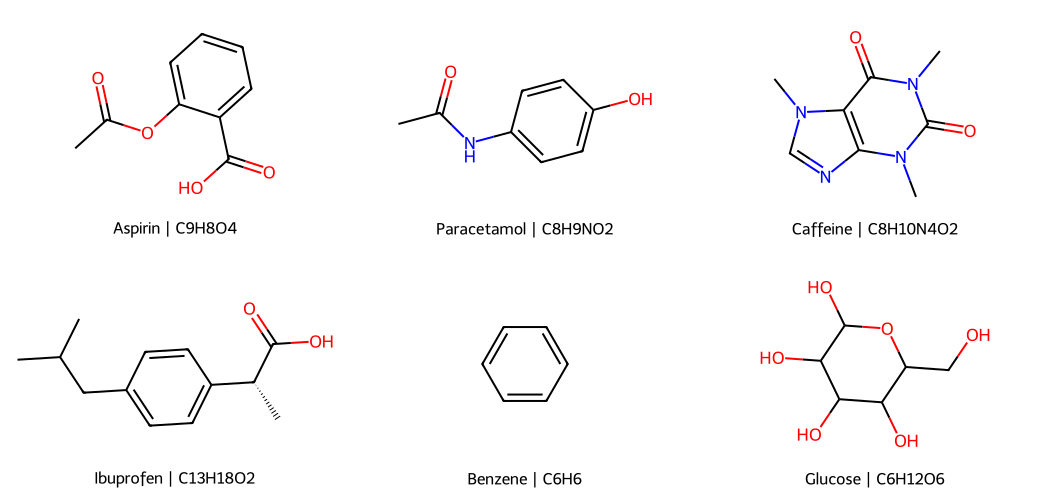

In [6]:
valid_df = df[df["valid"]].copy()

mols = valid_df["mol"].tolist()
legends = [
    f'{row["name"]} | {row["formula"]}'
    for _, row in valid_df.iterrows()
]

grid = Draw.MolsToGridImage(
    mols,
    molsPerRow=3,
    subImgSize=(350, 250),
    legends=legends
)

display(grid)

## 7. Morgan fingerprints and Tanimoto similarity

Morgan fingerprints encode local atom environments as a bit vector. The Tanimoto coefficient compares two fingerprints by looking at the bits they share relative to the bits present in either one.

Here I use Aspirin as the reference molecule. A score of `1.0` means the fingerprints are identical; a lower score means fewer bits are shared. It is a structural fingerprint similarity, not a measure of similar biological activity.

In [7]:
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

df["fingerprint"] = df["mol"].apply(
    lambda mol: morgan_generator.GetFingerprint(mol)
    if mol is not None else None
)

reference_name = "Aspirin"
reference_fp = df.loc[
    df["name"] == reference_name,
    "fingerprint"
].iloc[0]

df["TanimotoSimilarity"] = df["fingerprint"].apply(
    lambda fp: DataStructs.TanimotoSimilarity(reference_fp, fp)
    if fp is not None else np.nan
)

display(
    df[["name", "TanimotoSimilarity"]]
    .sort_values("TanimotoSimilarity", ascending=False)
    .round(3)
)

,name,TanimotoSimilarity
0,Aspirin,1.000
1,Paracetamol,0.222
3,Ibuprofen,0.195
4,Benzene,0.125
2,Caffeine,0.089
5,Glucose,0.025


## 8. Generate a 3D conformer

For a first 3D example I am using Aspirin. Hydrogens are added before generating coordinates. ETKDG generates an initial conformer, then MMFF is used to optimize its geometry.

This is a computed conformer, not an experimentally measured structure.

In [8]:
molecule_name = "Aspirin"

mol = df.loc[
    df["name"] == molecule_name,
    "mol"
].iloc[0]

mol_3d = Chem.AddHs(Chem.Mol(mol))

params = AllChem.ETKDGv3()
params.randomSeed = 42

status = AllChem.EmbedMolecule(mol_3d, params)

if status == 0:
    optimization_status = AllChem.MMFFOptimizeMolecule(mol_3d)
    print("3D conformer generated")
    print("MMFF optimization status:", optimization_status)
else:
    print("Conformer generation failed")

3D conformer generated
MMFF optimization status: 0


## 9. 3D view

Py3Dmol displays the coordinates generated in the previous cell. The viewer is interactive, so the molecule can be rotated and zoomed.

In [9]:
if mol_3d.GetNumConformers() > 0:
    pdb_block = Chem.MolToPDBBlock(mol_3d)

    viewer = py3Dmol.view(width=800, height=500)
    viewer.addModel(pdb_block, "pdb")
    viewer.setStyle({
        "stick": {"radius": 0.2},
        "sphere": {"scale": 0.3}
    })
    viewer.setBackgroundColor("white")
    viewer.zoomTo()
    viewer.show()
else:
    print("No 3D conformer to display")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 10. Export the results

I am saving the descriptor and functional-group results as CSV files. The RDKit molecule objects and fingerprint objects stay out of the CSV because they are not regular tabular values.

This is just a small export test for now. Later the dataset structure will probably need to be adjusted depending on how ChemLens stores molecules.

In [10]:
output_columns = [
    "name",
    "smiles",
    "canonical_smiles",
    "formula",
    "MolecularWeight",
    "ExactMass",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount",
    "HeavyAtoms",
    "FractionCSP3",
    "FunctionalGroups",
    "FunctionalGroupCount",
    "TanimotoSimilarity"
]

chem_df = df[output_columns].copy()
chem_df.to_csv("outputs/molecular_dataset.csv", index=False)
functional_group_df.to_csv("outputs/functional_groups.csv")

display(chem_df.round(3))

,name,smiles,canonical_smiles,formula,MolecularWeight,ExactMass,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,HeavyAtoms,FractionCSP3,FunctionalGroups,FunctionalGroupCount,TanimotoSimilarity
0,Aspirin,CC(=O)Oc1ccccc1C(=O)O,CC(=O)Oc1ccccc1C(=O)O,C9H8O4,180.159,180.042,1.310,63.60,1,3,2,1,13,0.111,"[Carboxylic acid, Ester, Ether, Six-membered a...",4,1.000
1,Paracetamol,CC(=O)Nc1ccc(O)cc1,CC(=O)Nc1ccc(O)cc1,C8H9NO2,151.165,151.063,1.351,49.33,2,2,1,1,11,0.125,"[Amide, Phenol, Six-membered aromatic ring]",3,0.222
2,Caffeine,Cn1c(=O)c2c(ncn2C)n(C)c1=O,Cn1c(=O)c2c(ncn2C)n(C)c1=O,C8H10N4O2,194.194,194.080,-1.029,61.82,0,3,0,2,14,0.375,[Six-membered aromatic ring],1,0.089
3,Ibuprofen,CC(C)Cc1ccc(cc1)[C@@H](C)C(=O)O,CC(C)Cc1ccc([C@@H](C)C(=O)O)cc1,C13H18O2,206.285,206.131,3.073,37.30,1,1,4,1,15,0.462,"[Carboxylic acid, Six-membered aromatic ring]",2,0.195
4,Benzene,c1ccccc1,c1ccccc1,C6H6,78.114,78.047,1.687,0.00,0,0,0,1,6,0.000,[Six-membered aromatic ring],1,0.125
5,Glucose,C(C1C(C(C(C(O1)O)O)O)O)O,OCC1OC(O)C(O)C(O)C1O,C6H12O6,180.156,180.063,-3.221,110.38,5,6,1,1,12,1.000,"[Alcohol, Ether]",2,0.025


## Notes / things to try next

- Add a few more molecules and check how the descriptor table changes.
- Try a different reference molecule for the Tanimoto comparison.
- Add more SMARTS patterns and check whether any of them overlap.
- Generate a 3D conformer for another molecule.

For now, the notebook is mainly an introduction to the RDKit workflow. The next step could be moving the repeated operations into reusable Python functions for ChemLens.